<a href="https://colab.research.google.com/github/junkim-researcher/turboquant-study1/blob/main/notebooks/exp0_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 0단계(E0) 재현 검증: TurboQuant mse / prod

**사용법:** 메뉴 **[런타임] → [모두 실행]** 한 번이면 끝나요. (CPU 런타임으로 충분, 약 1분)

실행이 끝나면 **[파일] → [GitHub에 사본 저장]** → 저장소 `junkim-researcher/turboquant-study1`, 파일 경로 `notebooks/exp0_colab.ipynb` 그대로 두고 **[확인]**. 실행 결과가 함께 저장돼서 Claude가 직접 확인할 수 있어요.

In [1]:
# 1) 코드 내려받기 (GitHub에서 최신 버전)
!rm -rf /content/turboquant-study1
!git clone -q https://github.com/junkim-researcher/turboquant-study1.git /content/turboquant-study1
%cd /content/turboquant-study1
!git log --oneline -1

/content/turboquant-study1
3c351f7 (HEAD -> main, origin/main, origin/HEAD) 0단계: TurboQuant 구현, 이론 예측표, 재현 검증, Colab 노트북


In [2]:
# 2) 한글 그래프용 글꼴 설치
!apt-get -qq install -y fonts-noto-cjk > /dev/null 2>&1
!rm -rf ~/.cache/matplotlib
print('글꼴 설치 완료')

글꼴 설치 완료


In [3]:
# 3) STEP 0: 이론 예측표
!python step0_predictions.py

   d  b |   D_b(직접)   D_b(논문) |    mse편향   mse분산×d |   prod분산×d    (논문) |    분산비
  64  2 |    0.1145     0.117 |  -11.45%    0.1014 |     0.5630   0.560 |   5.55
  64  3 |    0.0334     0.030 |   -3.34%    0.0323 |     0.1799   0.180 |   5.57
  64  4 |    0.0091     0.009 |   -0.91%    0.0090 |     0.0525   0.047 |   5.80
 128  2 |    0.1160     0.117 |  -11.60%    0.1025 |     0.5669   0.560 |   5.53
 128  3 |    0.0340     0.030 |   -3.40%    0.0328 |     0.1822   0.180 |   5.55
 128  4 |    0.0093     0.009 |   -0.93%    0.0092 |     0.0534   0.047 |   5.78


In [4]:
# 4) 0단계 재현 검증 (약 10~30초)
!python exp0_verify.py 2>&1 | grep -v findfont | tail -70


[C] MSE 재현
  d= 64 b=1  실측 0.35829 ± 0.00022  이론 0.35839  차이 -0.03%  PASS
  d= 64 b=2  실측 0.11437 ± 0.00011  이론 0.11453  차이 -0.14%  PASS
  d= 64 b=3  실측 0.03334 ± 0.00005  이론 0.03339  차이 -0.16%  PASS
  d= 64 b=4  실측 0.00912 ± 0.00002  이론 0.00913  차이 -0.13%  PASS
  d=128 b=1  실측 0.36112 ± 0.00014  이론 0.36089  차이 +0.06%  PASS
  d=128 b=2  실측 0.11613 ± 0.00008  이론 0.11600  차이 +0.11%  PASS
  d=128 b=3  실측 0.03403 ± 0.00003  이론 0.03397  차이 +0.18%  PASS
  d=128 b=4  실측 0.00932 ± 0.00001  이론 0.00931  차이 +0.03%  PASS

[D] 비편향성 (평균오차, z, ±2SE 안에 0?)
  d= 64 mse  b=1 ρ=0.1  평균오차 -0.03533  z= -8.82  0포함=False  추정/실제=0.6467 (mse이론 0.6416)
  d= 64 mse  b=1 ρ=0.5  평균오차 -0.18028  z=-48.27  0포함=False  추정/실제=0.6394 (mse이론 0.6416)
  d= 64 mse  b=1 ρ=0.9  평균오차 -0.32770  z=-133.77  0포함=False  추정/실제=0.6359 (mse이론 0.6416)
  d= 64 mse  b=2 ρ=0.1  평균오차 -0.00990  z= -3.65  0포함=False  추정/실제=0.9010 (mse이론 0.8855)
  d= 64 mse  b=2 ρ=0.5  평균오차 -0.05871  z=-18.09  0포함=False  추정/실제=0.8826 (mse이론 0.8855)
  d= 64 mse

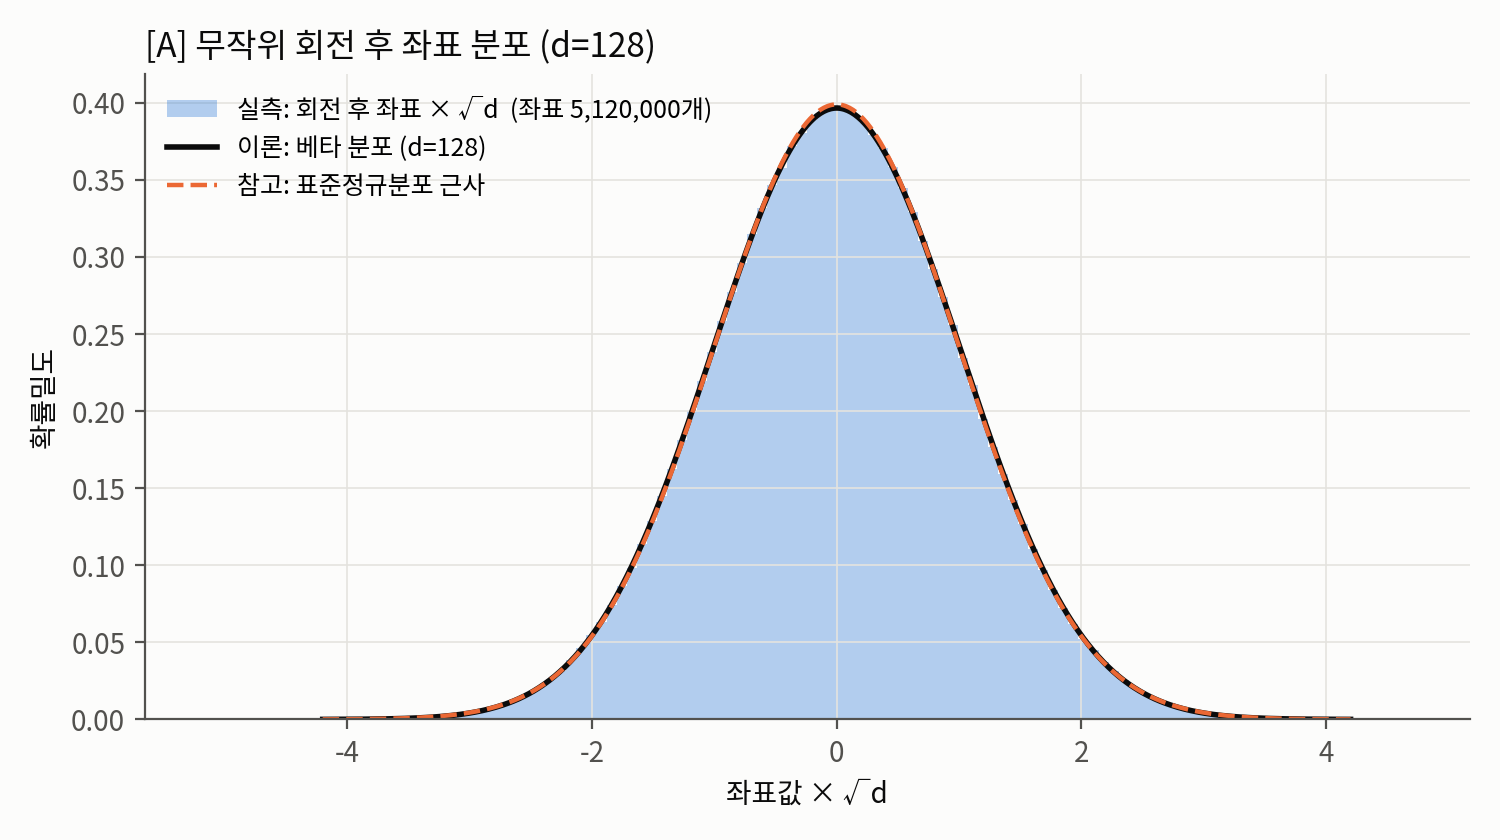

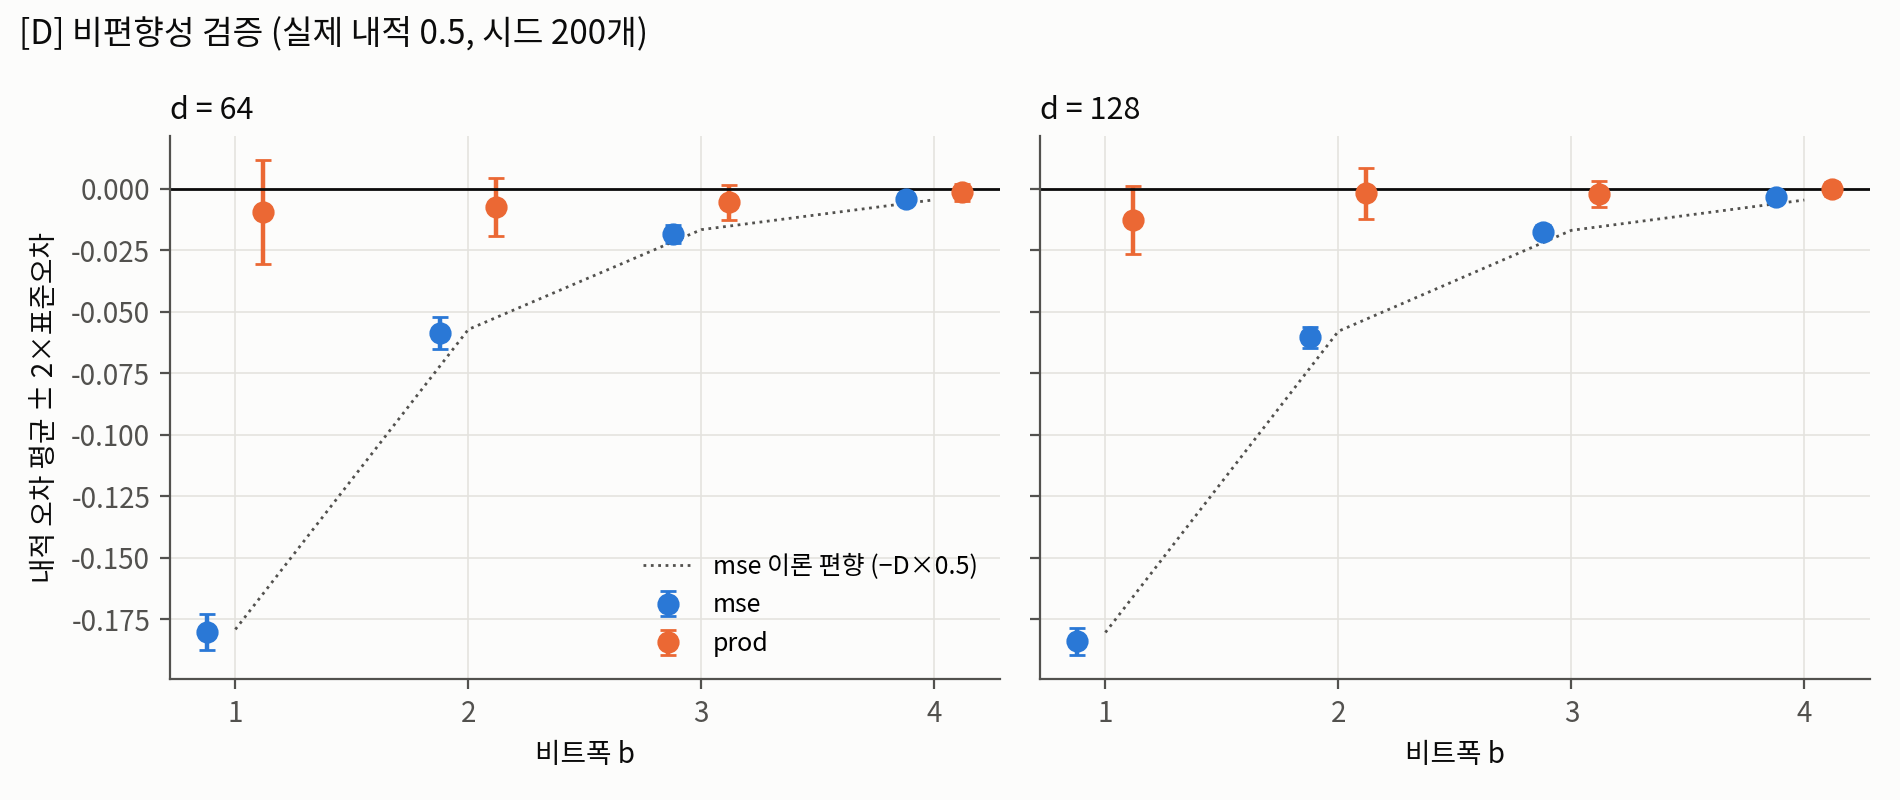

In [5]:
# 5) 그림 보기
from IPython.display import Image, display
display(Image('figures/e0_A_coord_hist.png', width=750))
display(Image('figures/e0_D_unbiasedness.png', width=900))

In [6]:
# 6) 판정 요약 (+ Claude 실행 결과와 대조)
!python summarize_exp0.py

 0단계(E0) 판정 요약
[A] 좌표 분포   KS p(베타)=0.323  통과
[B] 부호 보정   대각 양수 비율 보정O 0.500 / 보정X 0.228
[C] MSE 재현    8/8 조건 ±5% 이내, 최대 차이 0.18%
[D] prod 불편   22/24 조건에서 0 포함 (±2SE, 약 1개는 우연히 벗어날 수 있음)
[D] mse b=1     추정/실제 = 0.632 ~ 0.647  (2/π = 0.637)
[E] 저장 크기   계산식과 실측 일치
------------------------------------------------------------
Claude 실행 결과와의 최대 차이: 2.71e-13  →  같은 결과 (재현 성공)
실행 환경: torch 2.14.1+cpu, numpy 2.4.6, 실행 시간 9.4초
